In [1]:
# Put the repository root on sys.path, wherever the kernel was started from.
import os, sys

def _find_repo_root():
    _pkgs = ("genotyping", "pipelines", "screening", "sequencing")
    for _cand in [os.getcwd(), *sys.path]:
        if not _cand:
            continue
        _d = os.path.abspath(_cand)
        while True:
            if all(os.path.isdir(os.path.join(_d, _p)) for _p in _pkgs):
                return _d
            _parent = os.path.dirname(_d)
            if _parent == _d:
                break
            _d = _parent
    return None

_repo_root = _find_repo_root()
if _repo_root and _repo_root not in sys.path:
    sys.path.insert(0, _repo_root)



In [2]:
import os
import sys
from pathlib import Path
import glob
import re

import pandas as pd

from collections import defaultdict

from concurrent.futures import ProcessPoolExecutor
from concurrent.futures import as_completed

from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# path and configurations 

In [3]:
"""
Reference sequence
"""

REF_GENOME_DIR="."
ref_genome_file = os.path.join(REF_GENOME_DIR,"TnpB.fna")
with open(ref_genome_file, "r") as ref_file:
    ref_record = next(SeqIO.parse(ref_file, "fasta"))
ref_seq = ref_record.seq
ref_aa_seq = ref_record.seq.translate() # here translate are not correct this ref does contain start condon and start with w subunit,
                                         # only the nucleotide sequence is used downstream
ref_aa_seq_str = str(ref_aa_seq)
print(len(ref_seq))
print(ref_seq)
print(len(ref_aa_seq_str))
print(ref_aa_seq_str)

# os.system(f"bwa index {ref_genome_file }")

1254
ATGATCCGGAACAAGGCCTTCGTGGTGCGCCTGTACCCTAATGCCGCTCAGACCGAGCTGATCAACAGAACCCTCGGCAGCGCCCGGTTTGTGTACAACCACTTCCTGGCAAGAAGAATCGCCGCTTACAAGGAATCTGGCAAGGGCCTGACCTACGGCCAAACAAGCAGCGAGCTGACCCTGCTGAAGCAGGCCGAGGAAACCAGCTGGCTGTCTGAGGTGGACAAGTTCGCTCTGCAGAATAGCCTGAAGAACCTGGAAACCGCCTATAAGAATTTCTTCAGAACCGTGAAGCAGAGCGGCAAGAAAGTGGGCTTCCCAAGATTCAGAAAGAAGAGGACAGGCGAGAGCTACAGAACACAGTTCACCAACAACAACATCCAAATCGGCGAGGGCAGACTCAAGCTGCCCAAGCTGGGCTGGGTCAAGACCAAGGGCCAACAGGACATCCAGGGCAAAATCCTGAACGTGACCGTGCGGAGAATCCACGAAGGCCACTACGAGGCCTCTGTGCTGTGTGAAGTGGAAATCCCCTACCTGCCTGCTGCCCCTAAATTCGCCGCTGGTGTTGCTGTGGGAATTAAGGACTTCGCCATCGTGACCGACGGCGTGCGGTTTAAGCACGAGCAGAACCCCAAATACTACCGGAGCACCCTGAAAAGACTGCGGAAAGCCCAGCAGACCCTGAGCAGACGGAAAAAAGGCTCCGCCAGATACGGAAAGGCCAAGACCAAGCTGGCTAGGATCCATAAGCGGATCGTGAACAAGAGACAGGATTTTCTGCACAAACTGACGACCAGCCTGGTGAGAGAGTACGAGATCATTGGAACAGAGCACCTGAAGCCTGATAACATGAGAAAGAACCGCAGACTGGCCCTGAGCATCAGCGATGCCGGCTGGGGAGAATTCATCAGACAGCTGGAATACAAGGCTGCCTGGTACGGCAGACTTGTTTCCAAGGTGTCCCCTTACTTCCCATCTAGCCAGCTGTGCCA

In [4]:
META_DIR = "/mnt/mnemo1/Prance_meta_data"
DEST_ROOT_DIR = "/mnt/mnemo1/Pacbio_SpCas9"
RESULT_DEST_ROOT_DIR = "/mnt/G_Pharma/Users/tfang/Pacbio_SpCas9_old"

meta_files=["A8-04_PacBio_affmatt_PW_8May2025.xlsx",]
SOURCE_FASTQ_DIR_list = ["/mnt/G_Pharma/Users/omelko/PacBio/2025-04-07_PacBio_Bxb1_PW_PIDgrafted/PacBioRevio_PB304_20250401_o38071"]  # raw PacBio run folder

meta_files=[os.path.join(META_DIR,f) for f in meta_files]
for f in meta_files:
    print(f)
DEST_DIR_name=[re.search(r'\d+', os.path.basename(f)).group() for f in meta_files]
DEST_DIR_name="Priscila_A608"+"_".join(DEST_DIR_name)
print(DEST_DIR_name)

DEST_DIR=os.path.join(DEST_ROOT_DIR,DEST_DIR_name)
print(DEST_DIR)
Path(DEST_DIR).mkdir(exist_ok=True)
DEST_FASTQ_DIR =os.path.join(DEST_DIR,"fastqs_tp_demux") #'fastqs/tp_demux'
Path(DEST_FASTQ_DIR).mkdir(exist_ok=True)

out_folder=os.path.join(DEST_ROOT_DIR,DEST_DIR_name,"out")
Path(out_folder).mkdir(exist_ok=True)
print(out_folder)

RESULT_DIR=os.path.join(RESULT_DEST_ROOT_DIR,DEST_DIR_name)
Path(RESULT_DIR).mkdir(exist_ok=True)
result_folder=os.path.join(RESULT_DIR,"results")
Path(result_folder).mkdir(exist_ok=True)
print(result_folder)


/mnt/mnemo1/Prance_meta_data/A8-04_PacBio_affmatt_PW_8May2025.xlsx
Priscila_A6088
/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088
/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out
/mnt/G_Pharma/Users/tfang/Pacbio_SpCas9_old/Priscila_A6088/results


In [5]:
# congiguratoion files

min_reads_th = 100 # all samples that have few reads will be discusrded during analysis.

"""
Output files where processed read-level data is stored.
"""

base_dist_dir = Path(f'{out_folder}/base_dist')
base_dist_dir.mkdir(exist_ok=True)

def base_dist_file(sample):
    return base_dist_dir / (sample + '.base_dist.csv')

filtered_dir = Path(f'{out_folder}/filtered')
filtered_dir.mkdir(exist_ok=True)

def filtered_subs_file(sample):
    return filtered_dir / (sample + '.filter_subs.fasta')

gt_dir = Path(f'{out_folder}/gt_dist')
gt_dir.mkdir(exist_ok=True)

def gt_dist_file(sample):
    return gt_dir / (sample + ".gt_dist.csv")

aa_dist_dir = Path(f'{out_folder}/aa_dist')
aa_dist_dir.mkdir(exist_ok=True)

def aa_dist_file(sample):
    return aa_dist_dir / (sample + '.aa_dist.csv')

"""
Paths where to store important results
"""

samples_info = f'{result_folder}/samples_info.xlsx'
samples_info


'/mnt/G_Pharma/Users/tfang/Pacbio_SpCas9_old/Priscila_A6088/results/samples_info.xlsx'

In [6]:
consensus_meta_columns=['sample_name', 'multiplexed_sample', 'multiplexed_fastq','barcode_forward', 'barcode_reverse', 'timepoint', ]

meta_info_list=list()
for meta_file in meta_files:
    meta_info = pd.read_excel(meta_file, index_col=None)
    if "is_ctrl" in meta_info.columns:
        meta_info=meta_info.loc[meta_info["is_ctrl"]!=True,:]

    meta_info=meta_info.loc[:,consensus_meta_columns]
    print(meta_info.shape)

    # Append the processed dataframe to the list
    meta_info_list.append(meta_info)

# Merge all dataframes in the list into a single dataframe
merged_meta_info = pd.concat(meta_info_list, ignore_index=True)

merged_meta_info

(49, 6)


,sample_name,multiplexed_sample,multiplexed_fastq,barcode_forward,barcode_reverse,timepoint
0,A6-08_L0.2,A6-08_L0.2,Phage_A1-PW-A6-08_L0.2.fastq,TACAAT,TAAGAC,A6-08_L0.2
1,A6-08_L6,A6-08_L6,Phage_B1-PW-A6-08_L6.fastq,TACAAT,TAAGAC,A6-08_L6
2,A6-08_L7,A6-08_L7,Phage_C1-PW-A6-08_L7.fastq,TACAAT,TAAGAC,A6-08_L7
3,A6-08_L8,A6-08_L8,Phage_D1-PW-A6-08_L8.fastq,TACAAT,TAAGAC,A6-08_L8
4,A6-08_L9,A6-08_L9,Phage_E1-PW-A6-08_L9.fastq,TACAAT,TAAGAC,A6-08_L9
5,A6-08_L10,A6-08_L10,Phage_F1-PW-A6-08_L10.fastq,TACAAT,TAAGAC,A6-08_L10
6,A6-08_L11,A6-08_L11,Phage_G1-PW-A6-08_L11.fastq,TACAAT,TAAGAC,A6-08_L11
7,A6-08_L12,A6-08_L12,Phage_H1-PW-A6-08_L12.fastq,TACAAT,TAAGAC,A6-08_L12
8,A6-08_L13,A6-08_L13,Phage_A2-PW-A6-08_L13.fastq,TACAAT,TAAGAC,A6-08_L13
9,A6-08_L14,A6-08_L14,Phage_B2-PW-A6-08_L14.fastq,TACAAT,TAAGAC,A6-08_L14


In [7]:
# # check if all "sample_name" and "multiplexed_sample" are same, if so, no need to demultiplex
# # Check if all "sample_name" and "multiplexed_sample" are the same
# if merged_meta_info["sample_name"].equals(merged_meta_info["multiplexed_sample"]):
#     print("All 'sample_name' and 'multiplexed_sample' are the same. No need to demultiplex.")
# else:
#     print("Mismatch found between 'sample_name' and 'multiplexed_sample'. Demultiplexing is required.")

# check if mapping from timepoint and barcode is unique
timepoint_map = defaultdict(list)
for _, row in merged_meta_info.iterrows():
    timepoint = row["timepoint"]
    pair = (row["barcode_forward"], row["barcode_reverse"])
    timepoint_map[timepoint].append(pair)

timepoint_map={k:set(v) for k, v in timepoint_map.items()}

assert all([len(v)==1 for v in timepoint_map.values()])

In [8]:
pd.set_option('display.max_rows', 10)
meta_info=merged_meta_info
meta_info

,sample_name,multiplexed_sample,multiplexed_fastq,barcode_forward,barcode_reverse,timepoint
0,A6-08_L0.2,A6-08_L0.2,Phage_A1-PW-A6-08_L0.2.fastq,TACAAT,TAAGAC,A6-08_L0.2
1,A6-08_L6,A6-08_L6,Phage_B1-PW-A6-08_L6.fastq,TACAAT,TAAGAC,A6-08_L6
2,A6-08_L7,A6-08_L7,Phage_C1-PW-A6-08_L7.fastq,TACAAT,TAAGAC,A6-08_L7
3,A6-08_L8,A6-08_L8,Phage_D1-PW-A6-08_L8.fastq,TACAAT,TAAGAC,A6-08_L8
4,A6-08_L9,A6-08_L9,Phage_E1-PW-A6-08_L9.fastq,TACAAT,TAAGAC,A6-08_L9
...,...,...,...,...,...,...
44,A6-10_L12,A6-10_L12,Phage_A7-PW-A6-10_L12.fastq,TACAAT,TAAGAC,A6-10_L12
45,A6-10_L13,A6-10_L13,Phage_B7-PW-A6-10_L13.fastq,TACAAT,TAAGAC,A6-10_L13
46,A6-10_L14,A6-10_L14,Phage_C7-PW-A6-10_L14.fastq,TACAAT,TAAGAC,A6-10_L14
47,A6-10_L15,A6-10_L15,Phage_D7-PW-A6-10_L15.fastq,TACAAT,TAAGAC,A6-10_L15


# 1. demultiplex timepoint for each well  to different plates 
for both prance and evoflow data, each well contain samples collected from different plate at different timepoint
FGCZ center demultiplex data alredady to different well, now we need to different plate


In [9]:
import gzip
import shutil
from genotyping import pacbio_demultiplex

import importlib
importlib.reload(pacbio_demultiplex)

<module 'genotyping.pacbio_demultiplex' from '/home/tao/code/tnpb-analysis/genotyping/pacbio_demultiplex.py'>

In [10]:
# Filter to ensure each 'multiplex_fastq' has only one unique 'sample_name'
multiplexed_id_mapping = {
    # Using regular expression to handle both .fastq and .fastq.gz extensions
    k.split(".fastq")[0] if ".fastq.gz" not in k else k.split(".fastq.gz")[0]: v.iloc[0]
    for k, v in meta_info.groupby('multiplexed_fastq')['multiplexed_sample']
    if len(v.unique()) == 1
}

# The delivered fastq files are named by well only (Phage_A1.fastq), while the sample
# sheet lists the full name (Phage_A1-PW-A6-08_L0.2). Accept either spelling, so the
# filter below and pacbio_demultiplex.demultiplex_samples both resolve the sample.
multiplexed_id_mapping.update({k.split("-PW-")[0]: v for k, v in multiplexed_id_mapping.items()})

print(len(multiplexed_id_mapping))
print(list(multiplexed_id_mapping.items())[0:10])

98
[('Phage_A1-PW-A6-08_L0.2', 'A6-08_L0.2'), ('Phage_A2-PW-A6-08_L13', 'A6-08_L13'), ('Phage_A3-PW-A6-08_L21', 'A6-08_L21'), ('Phage_A4-PW-A6-08_L29', 'A6-08_L29'), ('Phage_A7-PW-A6-10_L12', 'A6-10_L12'), ('Phage_B1-PW-A6-08_L6', 'A6-08_L6'), ('Phage_B2-PW-A6-08_L14', 'A6-08_L14'), ('Phage_B3-PW-A6-08_L22', 'A6-08_L22'), ('Phage_B4-PW-A6-08_L30', 'A6-08_L30'), ('Phage_B5-PW-A6-09_L2', 'A6-09_L2')]


In [11]:
def get_fastq_files(fastaq_folder_list):
    fastq_files=list()
    for fastaq_folder in fastaq_folder_list:
        fastq_files.extend(glob.glob(f'{fastaq_folder}/*.fastq.gz'))
        fastq_files.extend(glob.glob(f'{fastaq_folder}/*.fastq'))
    return(fastq_files)

fastq_files = get_fastq_files(SOURCE_FASTQ_DIR_list)
print(len(fastq_files))
print(fastq_files[0])

fastq_files = [f  for f in fastq_files if Path(f).name.split(".fastq")[0] in multiplexed_id_mapping]
print(len(fastq_files))
print(fastq_files[0])

    

192
/mnt/G_Pharma/Users/omelko/PacBio/2025-04-07_PacBio_Bxb1_PW_PIDgrafted/PacBioRevio_PB304_20250401_o38071/Phage_H4.fastq
49
/mnt/G_Pharma/Users/omelko/PacBio/2025-04-07_PacBio_Bxb1_PW_PIDgrafted/PacBioRevio_PB304_20250401_o38071/Phage_H4.fastq


In [12]:
# List to collect DataFrames from each process
read_counts_all = []
demux_stats_all = []

with ProcessPoolExecutor() as executor:
    # Submit all the tasks and process them in parallel
    futures = [executor.submit(pacbio_demultiplex.demultiplex_samples, fastq_file,multiplexed_id_mapping, meta_info,DEST_FASTQ_DIR)
               for fastq_file in fastq_files]

    # Wait for all futures to complete and collect the results
    for future in futures:
        if future.result() is not None:
            read_counts, barcode_counts, demux_stats = future.result()
            read_counts_all.append(read_counts)
            demux_stats_all.append(demux_stats)

# take 4 minues  for 64 samples with 32 cpus

# now even with 16 samples, it takes 12  mintus even takes 42 mintus on second run, because now we write to G_drive,  the I/O is slow.
# or because now its not just fastq file ,but also fastqc file. 

In [13]:
# Concatenate all the DataFrames into a single DataFrame
merged_read_counts = pd.concat(read_counts_all, ignore_index=True)

# Function to check if a file is empty
def is_file_empty(file_path):
    return os.path.getsize(file_path) == 0

# Remove rows where the corresponding file is empty
# Its because now we use all barcode but not sample use all barcode so some emtpy files will be created
merged_read_counts = merged_read_counts[~merged_read_counts['fastq'].apply(is_file_empty)]
merged_read_counts

,Read Count,fastq
0,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
1,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
2,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
3,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
4,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
...,...,...
44,101729,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
45,142535,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
46,115494,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
47,71484,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...


In [14]:
merged_read_counts['Sample'] = merged_read_counts.fastq.map(lambda fastq: Path(fastq).name.split(".fastq")[0])

merged_read_counts = merged_read_counts.set_index('Sample')
merged_read_counts


,Read Count,fastq
Sample,,
A6-09_L8,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L28,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-09_L7,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L27,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L10,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
...,...,...
A6-09_L4,101729,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L13,142535,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L9,115494,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...


In [15]:

#to understand largoo, e.g. L4/1/13, co
# see the internal NERAI nomenclature document for lagoon naming

merged_read_counts.to_excel(f'{result_folder}/samples_info.xlsx')
merged_read_counts.head()

,Read Count,fastq
Sample,,
A6-09_L8,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L28,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-09_L7,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L27,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L10,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...


# 03_alignment to referece cas protein 

In [16]:
sam_dir = Path(f'{out_folder}/sam')
sam_dir.mkdir(exist_ok=True)

def sam_file(sample):
    return sam_dir / (sample + ".sam")

aligned_dir = Path(f'{out_folder}/aligned')
aligned_dir.mkdir(exist_ok=True)
def aligned_file(sample):
    return aligned_dir / (sample + '.aligned.fasta')

samples_info = pd.read_excel(f'{result_folder}/samples_info.xlsx', index_col=0)
sample_names = samples_info.index
fasta_files = samples_info.fastq
sam_files = sample_names.map(sam_file)
aligned_files = sample_names.map(aligned_file)

print(sample_names[0:3])
print(fasta_files[0:3] )
print(sam_files[0:3])
print(aligned_files[0:3])

Index(['A6-09_L8', 'A6-08_L28', 'A6-09_L7'], dtype='object', name='Sample')
Sample
A6-09_L8     /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-08_L28    /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
A6-09_L7     /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...
Name: fastq, dtype: object
Index([ /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/sam/A6-09_L8.sam,
       /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/sam/A6-08_L28.sam,
        /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/sam/A6-09_L7.sam],
      dtype='object', name='Sample')
Index([ /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L8.aligned.fasta,
       /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-08_L28.aligned.fasta,
        /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L7.aligned.fasta],
      dtype='object', name='Sample')


In [17]:
from genotyping import genotype
from genotyping import alignment

import importlib
importlib.reload(alignment)
importlib.reload(genotype)


<module 'genotyping.genotype' from '/home/tao/code/tnpb-analysis/genotyping/genotype.py'>

In [18]:
with ProcessPoolExecutor() as executor:
    # Align reads to the reference. Consume the iterator so a failure in any worker
    # is raised here, rather than leaving an empty alignment file to fail later.
    list(executor.map(alignment.run_bwa,
                      fasta_files, [ref_genome_file]*len(fasta_files), sam_files))

# this step is slow
# takes 23 mins for 1536 samples with 32 cpus

Running BWA command:
bwa mem -t 4 -k 19 -v 0 -A 1 -B 4 -O 20,20 -E 1,1 -L 5,5 ./TnpB.fna /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastqs_tp_demux/A6-08_L27.fastq
Running BWA command:
bwa mem -t 4 -k 19 -v 0 -A 1 -B 4 -O 20,20 -E 1,1 -L 5,5 ./TnpB.fna /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastqs_tp_demux/A6-08_L28.fastq
Running BWA command:
bwa mem -t 4 -k 19 -v 0 -A 1 -B 4 -O 20,20 -E 1,1 -L 5,5 ./TnpB.fna /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastqs_tp_demux/A6-09_L8.fastq
Running BWA command:
bwa mem -t 4 -k 19 -v 0 -A 1 -B 4 -O 20,20 -E 1,1 -L 5,5 ./TnpB.fna /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastqs_tp_demux/A6-08_L10.fastq
Running BWA command:
bwa mem -t 4 -k 19 -v 0 -A 1 -B 4 -O 20,20 -E 1,1 -L 5,5 ./TnpB.fna /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastqs_tp_demux/A6-09_L7.fastq
Running BWA command:
bwa mem -t 4 -k 19 -v 0 -A 1 -B 4 -O 20,20 -E 1,1 -L 5,5 ./TnpB.fna /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastqs_tp_demux/A6-10_L16.fastq
Running BWA command:
bwa mem -

In [19]:
with ProcessPoolExecutor() as executor:
    # Reconstruct sequences from alignment file, ignoring indels.
    # Deletions are filled with bases from reference genome. Insertions are discarded.
    # make analyis simple, and indel minght just be seq error
    results = executor.map(alignment.reconstruct_sequences_checkMaping,
                           sam_files, [ref_seq]*len(sam_files), aligned_files, sample_names)

results = list(results)

#for 1536  samples  with 32 cpus,takes  2 mins 

In [20]:
df_res = pd.DataFrame(results)
samples_info['total_reads'] = df_res.total_reads.values
samples_info['mapped_reads'] = df_res.mapped_reads.values
samples_info['full_reads'] = df_res.full_reads.values
samples_info.to_excel(f'{result_folder}/samples_info.xlsx')


In [21]:
samples = pd.read_excel(f'{result_folder}/samples_info.xlsx', index_col=0)
sample_names = samples.index

samples


,Read Count,fastq,total_reads,mapped_reads,full_reads
Sample,,,,,
A6-09_L8,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,102669,89,86
A6-08_L28,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,182899,45297,44590
A6-09_L7,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,73711,83,80
A6-08_L27,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,124628,53690,52820
A6-08_L10,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,97123,43027,42389
...,...,...,...,...,...
A6-09_L4,101729,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,101781,35630,34125
A6-08_L13,142535,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,142565,49080,48365
A6-08_L9,115494,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,115550,51661,51005


In [22]:
fasta_files = sample_names.map(aligned_file)
#before:  we filtering mutaions, at each base, if each mutations happens less 5%  and  replace mutation with wild types  as we think they are errors. check <path>
#but from the refence data, we found the mismatching rate is almost 0, so we drop this step.
# base_dist_files = sample_names.map(base_dist_file) # omit this to steps now as we
# filtered_subs_files = sample_names.map(filtered_subs_file)
gt_dist_files = sample_names.map(gt_dist_file)



In [23]:
with ProcessPoolExecutor() as executor:
    #collect different genotypes
    # measure by amino acid
    # Get prevalence of each genotype among sequences (in the same lagoon from same time point )
    # Genotype is a set of mutations.
    # consume the iterator so a failure in any worker is raised here
    list(executor.map(genotype.get_genotype_distribution,fasta_files, gt_dist_files, [ref_aa_seq]*len(fasta_files)))
# for 1536 samples with 32 gpus, takes 2m 46s


Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L7.aligned.fasta: 46 genotypes in 80 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L8.aligned.fasta: 45 genotypes in 86 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L6.aligned.fasta: 2515 genotypes in 28246 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L5.aligned.fasta: 1578 genotypes in 30048 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-08_L31.aligned.fasta: 3461 genotypes in 33464 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L14.aligned.fasta: 1704 genotypes in 38232 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-08_L20.aligned.fasta: 6324 genotypes in 35053 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L9.aligned.fasta: 2081 genotypes in 44186 reads
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L8

# 06_mutation_calling  
here mean point mutation 

In [24]:
samples = pd.read_excel(f'{result_folder}/samples_info.xlsx', index_col=0)
sample_names = samples.index
samples


,Read Count,fastq,total_reads,mapped_reads,full_reads
Sample,,,,,
A6-09_L8,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,102669,89,86
A6-08_L28,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,182899,45297,44590
A6-09_L7,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,73711,83,80
A6-08_L27,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,124628,53690,52820
A6-08_L10,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,97123,43027,42389
...,...,...,...,...,...
A6-09_L4,101729,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,101781,35630,34125
A6-08_L13,142535,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,142565,49080,48365
A6-08_L9,115494,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,115550,51661,51005


In [25]:
aligned_files = sample_names.map(aligned_file)
aa_dist_files = sample_names.map(aa_dist_file)

In [26]:

with ProcessPoolExecutor() as executor:
    # for each refence, for each postion, distribution of different amino acid
    # unlike the genotype distribution, this ignores mutation combinations
    # this is done for each lagoon at certin timepoint
    # consume the iterator so a failure in any worker is raised here
    list(executor.map(genotype.compute_aa_dist, aligned_files, aa_dist_files, [len(ref_seq)]*len(fasta_files)))

# for 1536 samples with 32 cpus, takes 3 min


Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L7.aligned.fasta: time 0.04s, wrong length in 0/80Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L8.aligned.fasta: time 0.04s, wrong length in 0/86

Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L6.aligned.fasta: time 8.05s, wrong length in 0/28246
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L11.aligned.fasta: time 8.33s, wrong length in 0/28407
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-10_L5.aligned.fasta: time 8.57s, wrong length in 0/30048
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-09_L6.aligned.fasta: time 8.97s, wrong length in 0/31034
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-08_L31.aligned.fasta: time 9.57s, wrong length in 0/33464
Processed /mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/aligned/A6-08_L20.aligned.fasta: time 10.12s, wrong length in 0/35053
Processed /mnt/mne

# collect top genotypes and top mutations 

2024-11-14_prance-lagoons.xlsx # this meta is autamatical generated from Prance robot, need to be updated here regulally

In [27]:
samples = pd.read_excel(f'{result_folder}/samples_info.xlsx')
samples['gt_dist'] = samples.Sample.map(gt_dist_file)
samples['aa_dist'] = samples.Sample.map(aa_dist_file)
print(samples.shape)

samples=samples.set_index('Sample')

# prance_lagoons = pd.read_excel(os.path.join(META_DIR,'2024-11-14_prance-lagoons.xlsx'))
# print(prance_lagoons.shape)

# samples = pd.merge(samples, prance_lagoons, left_on='Lagoon', right_on='lagoon', how='left',).set_index('Sample')

# # Assert that no rows have NaN in the 'lagoon' column from the right DataFrame,except the control group
# assert samples.loc[samples.Timepoint!="tp00",'Lagoon'].notna().all(), "Some rows in 'samples' did not find a matching record in 'prance_lagoons'"

# assert samples.loc[samples["dilution_rate"].isnull()].Timepoint.nunique() == 1 # for the lagoon at time 0, it has not info of qpcr, dilution rate and so on.

# samples



(49, 8)


In [28]:
f_samples=samples

In [29]:
def collect_all_gts(s, gt_dist):
    gt_dist = pd.read_csv(gt_dist)
    top_frac = gt_dist['Fraction'].values.tolist()
    top_gt_mutations = gt_dist['Mutations'].values.tolist()
    return s, top_gt_mutations, top_frac

with ProcessPoolExecutor() as executor:
    results = [executor.submit(collect_all_gts, s, f_samples.loc[s, 'gt_dist']) for s in f_samples.index]
    results = [r.result() for r in as_completed(results)]

gt_frac_threshold=0.0 # 0.01
top_gt_all_samples = list()
for result in results:
    s, top_gt_mutations, top_frac = result
    #sample_meta_info = samples.loc[s, ['campaign', 'Lagoon', 'Well', 'Timepoint', 'PAM', 'Read Count', 'full_reads']].tolist()
    sample_meta_info = samples.loc[s,  ['Read Count', 'full_reads']].tolist()
    for mutation, frac in zip(top_gt_mutations, top_frac):
        if frac > gt_frac_threshold:  # Filter mutations with fraction greater than 0.01
            top_gt_all_samples.append([s, mutation, frac] + sample_meta_info + [Path(ref_genome_file).stem])

top_gt_all_samples = pd.DataFrame(top_gt_all_samples,
                                  columns=["Sample", 'top_gt_mutations', 'top_frac', 'Read Count', 'full_reads', "ref_genome"])
                                #   columns=["Sample", 'top_gt_mutations', 'top_frac', 'campaign', 'Lagoon', 'Well', 'Timepoint', 'PAM', 'Read Count', 'full_reads', "ref_genome"])

print(top_gt_all_samples.shape)
top_gt_all_samples.to_csv(f'{result_folder}/top_gt_samples_filtered_{gt_frac_threshold}.csv', header=True, index=None, sep="\t")

# 2 mintues



(320617, 6)


In [30]:
muts_filtered_per_sample = {}
aamutation_min_frac_th=0.0

with ProcessPoolExecutor() as executor:
    # Create futures for each sample
    futures = {
        executor.submit(genotype.filter_muts_per_sample, aa_dist, ref_aa_seq, aamutation_min_frac_th): sample_name
        for sample_name, aa_dist in f_samples.aa_dist.items()
    }

    # Collect results as they complete
    for future in as_completed(futures):
        sample_name = futures[future]
        muts_filtered_per_sample[sample_name] = future.result()

muts_filtered_all_samples=list()
for sample_name,df in muts_filtered_per_sample.items():
    #sample_meta_info=samples.loc[sample_name,['campaign','Lagoon','Well','Timepoint','PAM', 'Read Count',  'full_reads',]].tolist()
    sample_meta_info=samples.loc[sample_name,[ 'Read Count',  'full_reads',]].tolist()
    muts_filtered_all_samples.extend([[sample_name,index] + row.tolist() + sample_meta_info+[Path(ref_genome_file).stem] for index, row in df.iterrows()])

muts_filtered_all_samples=pd.DataFrame(muts_filtered_all_samples,
                            columns=["Sample",'Position', 'TopMutation', 'Fraction','Read Count',  'full_reads',"ref_name"])
                            #columns=["Sample",'Position', 'TopMutation', 'Fraction','campaign','Lagoon','Well','Timepoint','PAM', 'Read Count',  'full_reads',"ref_name"])
# Sample -> timepoint label, as used further down where real_time_point is the sample name.
meta_info_dict = dict(zip(meta_info['multiplexed_sample'], meta_info['timepoint']))
muts_filtered_all_samples['real_time_point'] = muts_filtered_all_samples['Sample'].map(meta_info_dict)

muts_filtered_all_samples.to_csv(f'{result_folder}/point_mutations_noFiltering_all_samples.csv',header=True,index=None,sep="\t")

# 3 minutes 

In [31]:
top_muts_filtered_per_sample = {}
aamutation_min_frac_th=0.0

with ProcessPoolExecutor() as executor:
    # Create futures for each sample
    futures = {
        executor.submit(genotype.filter_top_muts_per_sample, aa_dist, ref_aa_seq, aamutation_min_frac_th): sample_name
        for sample_name, aa_dist in f_samples.aa_dist.items()
    }

    # Collect results as they complete
    for future in as_completed(futures):
        sample_name = futures[future]
        top_muts_filtered_per_sample[sample_name] = future.result()

top_muts_filtered_all_samples=list()
for sample_name,df in top_muts_filtered_per_sample.items():
    #sample_meta_info=samples.loc[sample_name,['campaign','Lagoon','Well','Timepoint','PAM', 'Read Count',  'full_reads',]].tolist()
    sample_meta_info=samples.loc[sample_name,[ 'Read Count',  'full_reads',]].tolist()
    top_muts_filtered_all_samples.extend([[sample_name,index] + row.tolist() + sample_meta_info+[Path(ref_genome_file).stem] for index, row in df.iterrows()])

top_muts_filtered_all_samples=pd.DataFrame(top_muts_filtered_all_samples,
                                           columns=["Sample",'Position', 'TopMutation', 'Fraction', 'Read Count',  'full_reads',"ref_name"])
                            #columns=["Sample",'Position', 'TopMutation', 'Fraction','campaign','Lagoon','Well','Timepoint','PAM', 'Read Count',  'full_reads',"ref_name"])

top_muts_filtered_all_samples.to_csv(f'{result_folder}/top_point_mutations_noFiltering_all_samples.csv',header=True,index=None,sep="\t")
# 2mins



In [32]:
top_muts_filtered_per_sample = {}
aamutation_min_frac_th=0.2

with ProcessPoolExecutor() as executor:
    # Create futures for each sample
    futures = {
        executor.submit(genotype.filter_top_muts_per_sample, aa_dist, ref_aa_seq, aamutation_min_frac_th): sample_name
        for sample_name, aa_dist in f_samples.aa_dist.items()
    }

    # Collect results as they complete
    for future in as_completed(futures):
        sample_name = futures[future]
        top_muts_filtered_per_sample[sample_name] = future.result()

top_muts_filtered_all_samples=list()
for sample_name,df in top_muts_filtered_per_sample.items():
    #sample_meta_info=samples.loc[sample_name,['campaign','Lagoon','Well','Timepoint','PAM', 'Read Count',  'full_reads',]].tolist()
    sample_meta_info=samples.loc[sample_name,['Read Count',  'full_reads',]].tolist()
    top_muts_filtered_all_samples.extend([[sample_name,index] + row.tolist() + sample_meta_info+[Path(ref_genome_file).stem] for index, row in df.iterrows()])

top_muts_filtered_all_samples=pd.DataFrame(top_muts_filtered_all_samples,
                                           columns=["Sample",'Position', 'TopMutation', 'Fraction', 'Read Count',  'full_reads',"ref_name"])
                            #columns=["Sample",'Position', 'TopMutation', 'Fraction','campaign','Lagoon','Well','Timepoint','PAM', 'Read Count',  'full_reads',"ref_name"])

top_muts_filtered_all_samples.to_csv(f'{result_folder}/top_point_mutations_filtered_all_samples.csv',header=True,index=None,sep="\t")

# 1 minutes


# ploting 

In [33]:
top_muts_filtered_all_samples=pd.read_csv(f'{result_folder}/top_point_mutations_noFiltering_all_samples.csv',header=0,sep="\t",index_col=None)
print(top_muts_filtered_all_samples.shape)
top_muts_filtered_all_samples.head(n=100)

(19564, 7)


,Sample,Position,TopMutation,Fraction,Read Count,full_reads,ref_name
0,A6-09_L8,16,V,0.244186,102668,86,TnpB
1,A6-09_L8,19,D,0.011628,102668,86,TnpB
2,A6-09_L8,22,D,0.023256,102668,86,TnpB
3,A6-09_L8,23,K,0.511628,102668,86,TnpB
4,A6-09_L8,44,N,0.011628,102668,86,TnpB
...,...,...,...,...,...,...,...
95,A6-10_L14,48,Q,0.000157,129846,38232,TnpB
96,A6-10_L14,49,A,0.000131,129846,38232,TnpB
97,A6-10_L14,50,Q,0.000026,129846,38232,TnpB
98,A6-10_L14,51,A,0.000026,129846,38232,TnpB


In [34]:

top_muts_filtered_all_samples['MutationTypes'] = top_muts_filtered_all_samples.apply(lambda x: str(ref_aa_seq[x['Position']-1])+str(x['Position'])+x['TopMutation'], axis=1)
top_muts_filtered_all_samples



,Sample,Position,TopMutation,Fraction,Read Count,full_reads,ref_name,MutationTypes
0,A6-09_L8,16,V,0.244186,102668,86,TnpB,A16V
1,A6-09_L8,19,D,0.011628,102668,86,TnpB,E19D
2,A6-09_L8,22,D,0.023256,102668,86,TnpB,N22D
3,A6-09_L8,23,K,0.511628,102668,86,TnpB,R23K
4,A6-09_L8,44,N,0.011628,102668,86,TnpB,K44N
...,...,...,...,...,...,...,...,...
19559,A6-08_L22,412,G,0.000162,101961,55691,TnpB,D412G
19560,A6-08_L22,413,L,0.000144,101961,55691,TnpB,P413L
19561,A6-08_L22,414,N,0.000090,101961,55691,TnpB,K414N
19562,A6-08_L22,415,N,0.000970,101961,55691,TnpB,K415N


In [35]:
selected_MutationTypes=top_muts_filtered_all_samples.loc[top_muts_filtered_all_samples["Fraction"]>0.05,"MutationTypes"].unique()
print(len(selected_MutationTypes))

21


In [36]:
import seaborn as sns

import matplotlib.pyplot as plt

# Filter rows: keep only those mutations in selected_MutationTypes
df_filtered = top_muts_filtered_all_samples[top_muts_filtered_all_samples["MutationTypes"].isin(selected_MutationTypes)]

# Create a pivot table with MutationTypes as rows, real_time_point as columns, using the mean of Fraction as values
Muts = df_filtered.pivot_table(index="MutationTypes",
                                         columns="Sample",
                                         values="Fraction",)

Muts = Muts.fillna(0)
Muts.head(n=10)


Sample,A6-08_L0.2,A6-08_L10,A6-08_L11,A6-08_L12,A6-08_L13,A6-08_L14,A6-08_L15,A6-08_L16,A6-08_L17,A6-08_L18,...,A6-10_L12,A6-10_L13,A6-10_L14,A6-10_L15,A6-10_L16,A6-10_L5,A6-10_L6,A6-10_L7,A6-10_L8,A6-10_L9
MutationTypes,,,,,,,,,,,,,,,,,,,,,
A16V,0.000170,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001624,0.000000,...,0.000111,0.000831,0.000026,0.000505,0.000292,0.000532,0.000389,0.000467,0.000381,0.000407
A375G,0.997059,0.989431,0.990089,0.987604,0.987450,0.991672,0.968824,0.995851,0.991374,0.992451,...,0.992723,0.995465,0.996678,0.997474,0.995684,0.996672,0.994690,0.993484,0.992873,0.995406
A376V,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003247,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
D333Y,0.000094,0.000000,0.000000,0.000000,0.005024,0.000000,0.000000,0.000000,0.000000,0.113180,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000100,0.000000,0.000000,0.000000,0.000000
E116G,0.000057,0.000779,0.001572,0.001826,0.001778,0.000985,0.000234,0.002093,0.000487,0.054958,...,0.000000,0.000045,0.000000,0.000000,0.000000,0.000000,0.000283,0.000093,0.000000,0.000000
F93S,0.000057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.001991,0.000404,0.000105,0.000054,0.000000,0.000000,0.000248,0.000234,0.000000,0.000000
G335C,0.999114,0.998207,0.998865,0.997980,0.998305,0.997887,0.998379,0.999196,0.999168,0.999133,...,0.998872,0.997777,0.999032,0.999206,0.998989,0.998835,0.997345,0.997174,0.997712,0.997443
I199V,0.999076,0.997735,0.997380,0.998008,0.998015,0.998974,0.997821,0.999084,0.998884,0.999082,...,0.999558,0.996902,0.999268,0.999296,0.999378,0.998835,0.997486,0.997454,0.998165,0.998801
K233E,0.000415,0.011442,0.017224,0.018870,0.012075,0.011979,0.017902,0.019680,0.007063,0.004157,...,0.001017,0.000651,0.000915,0.003735,0.000544,0.001464,0.001664,0.001565,0.001978,0.000679


In [37]:
Muts_Pace1=Muts.loc[:,Muts.columns.str.contains("A6-08")]
Muts_Pace1

Sample,A6-08_L0.2,A6-08_L10,A6-08_L11,A6-08_L12,A6-08_L13,A6-08_L14,A6-08_L15,A6-08_L16,A6-08_L17,A6-08_L18,...,A6-08_L29,A6-08_L30,A6-08_L31,A6-08_L32,A6-08_L33,A6-08_L34,A6-08_L6,A6-08_L7,A6-08_L8,A6-08_L9
MutationTypes,,,,,,,,,,,,,,,,,,,,,
A16V,0.000170,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001624,0.000000,...,0.401971,0.438972,0.488973,0.526602,0.530230,0.470096,0.000000,0.000836,0.001199,0.001255
A375G,0.997059,0.989431,0.990089,0.987604,0.987450,0.991672,0.968824,0.995851,0.991374,0.992451,...,0.995390,0.994824,0.995338,0.996242,0.996779,0.996059,0.994221,0.994252,0.991350,0.991236
A376V,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003247,0.000000,...,0.045725,0.025818,0.004811,0.003259,0.005198,0.007042,0.000000,0.000000,0.000000,0.000000
D333Y,0.000094,0.000000,0.000000,0.000000,0.005024,0.000000,0.000000,0.000000,0.000000,0.113180,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000978,0.000000,0.000000,0.000000
E116G,0.000057,0.000779,0.001572,0.001826,0.001778,0.000985,0.000234,0.002093,0.000487,0.054958,...,0.005758,0.003064,0.002839,0.000633,0.001916,0.001516,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
R23K,0.000603,0.002902,0.002423,0.003542,0.002233,0.001538,0.001441,0.002859,0.002963,0.200704,...,0.974694,0.978682,0.978574,0.988151,0.986241,0.984704,0.001434,0.001529,0.002098,0.002039
S267R,0.000000,0.002784,0.003689,0.003431,0.003246,0.001272,0.001675,0.001103,0.002496,0.001607,...,0.001959,0.023346,0.001823,0.000882,0.002405,0.000000,0.001651,0.001936,0.001918,0.002490
S294N,0.000075,0.003562,0.004453,0.003984,0.004342,0.003795,0.004611,0.000000,0.000792,0.088748,...,0.004887,0.003549,0.003974,0.001189,0.001651,0.001376,0.000978,0.001732,0.002078,0.001823


In [38]:
samples = pd.read_excel(f'{result_folder}/samples_info.xlsx', index_col=0)
samples['real_time_point'] = samples.index
samples['real_time_point_1'] = samples['real_time_point'].apply(lambda x: float(x.split('_L')[-1]))

samples_1=samples.loc[samples['real_time_point'].str.contains("A6-08"),:]
samples_1

samples_2=samples.loc[samples['real_time_point'].str.contains("A6-09"),:]
samples_2

samples_3=samples.loc[samples['real_time_point'].str.contains("A6-10"),:]
samples_3

samples_2

,Read Count,fastq,total_reads,mapped_reads,full_reads,real_time_point,real_time_point_1
Sample,,,,,,,
A6-09_L8,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,102669,89,86,A6-09_L8,8.0
A6-09_L7,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,73711,83,80,A6-09_L7,7.0
A6-09_L3,115194,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,115240,42008,39547,A6-09_L3,3.0
A6-09_L6,113631,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,113667,32373,31034,A6-09_L6,6.0
A6-09_L2,110203,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,110267,56952,56434,A6-09_L2,2.0
A6-09_L5,126003,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,126036,37669,36167,A6-09_L5,5.0
A6-09_L4,101729,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,101781,35630,34125,A6-09_L4,4.0


Index(['L0.2', 'L6', 'L7', 'L8', 'L9', 'L10', 'L11', 'L12', 'L13', 'L14',
       'L15', 'L16', 'L17', 'L18', 'L19', 'L20', 'L21', 'L22', 'L23', 'L24',
       'L25', 'L26', 'L27', 'L28', 'L29', 'L30', 'L31', 'L32', 'L33', 'L34'],
      dtype='object')
(21, 30)
(1, 30)


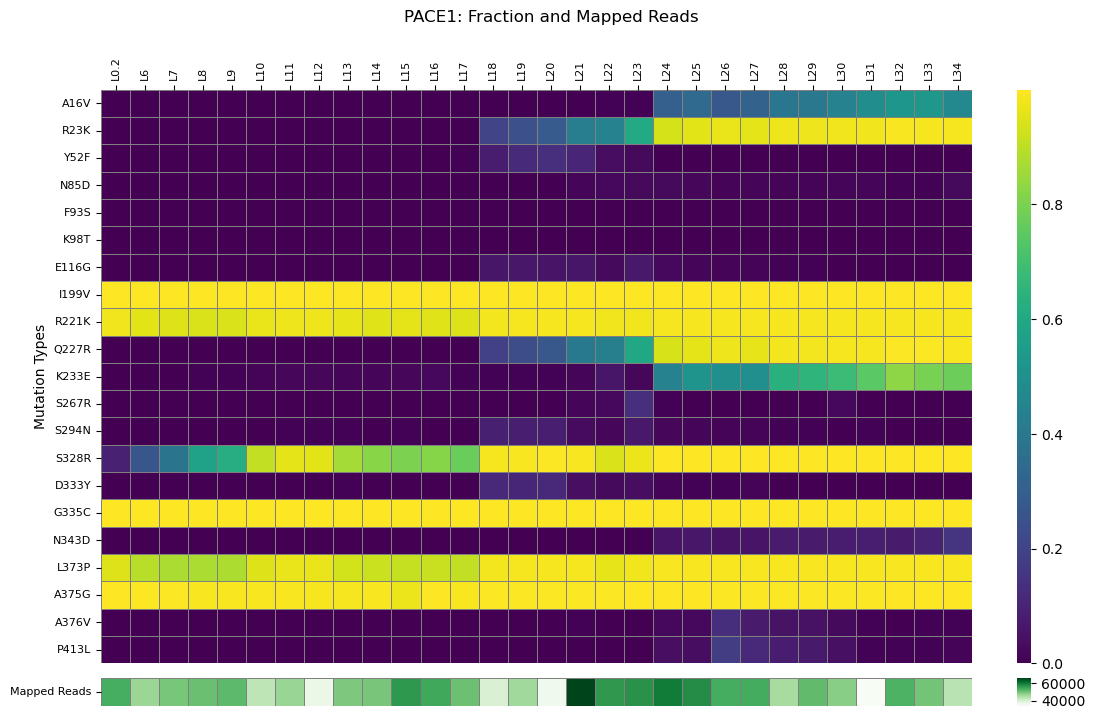

In [39]:
def plot_fraction_ct_lagoon_mapped_heatmap(heatmap_data, samples, figsize=(20, 16), cmap="viridis", title=""):
    import matplotlib.gridspec as gridspec
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt

    # Sort columns based on the numeric value after '_T'
    sorted_columns = sorted(heatmap_data.columns, key=lambda col: float(col.split('_L')[-1]))
    hours = [float(col.split('_L')[-1]) for col in sorted_columns]

    # Mapped reads
    mapped_reads = samples.set_index("real_time_point_1").reindex(hours)["mapped_reads"].values

    # Reorder heatmap_data and adjust column labels
    heatmap_data = heatmap_data.reindex(columns=sorted_columns)
    heatmap_data.columns = [col.split("_")[-1] for col in heatmap_data.columns]
    print(heatmap_data.columns)

    try:
        sorted_index = sorted(heatmap_data.index, key=lambda x: int(x[1:-1]))
    except Exception:
        sorted_index = heatmap_data.index
    heatmap_data = heatmap_data.reindex(index=sorted_index)
    print(heatmap_data.shape)

    # Set up a gridspec with two rows; the top is larger
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(2, 2, width_ratios=[len(heatmap_data.columns), 0.5],
                           height_ratios=[len(heatmap_data.index), 1],
                           wspace=0.1, hspace=0.05)

    # Top: Fraction heatmap
    ax0 = plt.subplot(gs[0,0])
    ax0_cbar= plt.subplot(gs[0, 1])  # color bar at row 0, column 1
    sns.heatmap(heatmap_data, cmap=cmap, ax=ax0, cbar=True, cbar_ax=ax0_cbar,
                xticklabels=heatmap_data.columns, yticklabels=heatmap_data.index,
                linewidths=0.5, linecolor='gray')  # Add grid lines
    ax0.set_yticklabels(ax0.get_yticklabels(), rotation=0, fontsize=8)
    ax0.set_ylabel("Mutation Types")
    ax0.xaxis.tick_top()
    max_ticks = 100  # Maximum number of x-tick labels to display
    n_columns = len(heatmap_data.columns)
    if n_columns > max_ticks:
        tick_indices = np.linspace(0, n_columns - 1, max_ticks, dtype=int)
        ax0.set_xticks(tick_indices)
        ax0.set_xticklabels([heatmap_data.columns[i] for i in tick_indices], rotation=90, fontsize=8)
    else:
        ax0.set_xticklabels(ax0.get_xticklabels(), rotation=90, fontsize=8)

    # Second: mapped_reads heatmap
    mapped_array = np.reshape(mapped_reads, (1, -1))
    print(mapped_array.shape)
    ax1 = plt.subplot(gs[1,0])
    ax1_cbar = plt.subplot(gs[1, 1])  # color bar at row 1, column 1
    sns.heatmap(mapped_array, cmap="Greens", ax=ax1, cbar=True, cbar_ax=ax1_cbar,
                xticklabels=False, yticklabels=["Mapped Reads"],
                linewidths=0.5, linecolor='gray')  # Add grid lines
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=8)

    plt.suptitle(title)
    plt.show()

    return fig

# Example usage:
plot_fraction_ct_lagoon_mapped_heatmap(Muts_Pace1, samples_1,
                                       figsize=(12, 8), cmap="viridis",
                                       title="PACE1: Fraction and Mapped Reads");


Index(['L0.2', 'L6', 'L7', 'L8', 'L9', 'L10', 'L11', 'L12', 'L13', 'L14',
       'L15', 'L16', 'L17', 'L18', 'L19', 'L20', 'L21', 'L22', 'L23', 'L24',
       'L25', 'L26', 'L27', 'L28', 'L29', 'L30', 'L31', 'L32', 'L33', 'L34'],
      dtype='object')
(8, 30)
(1, 30)


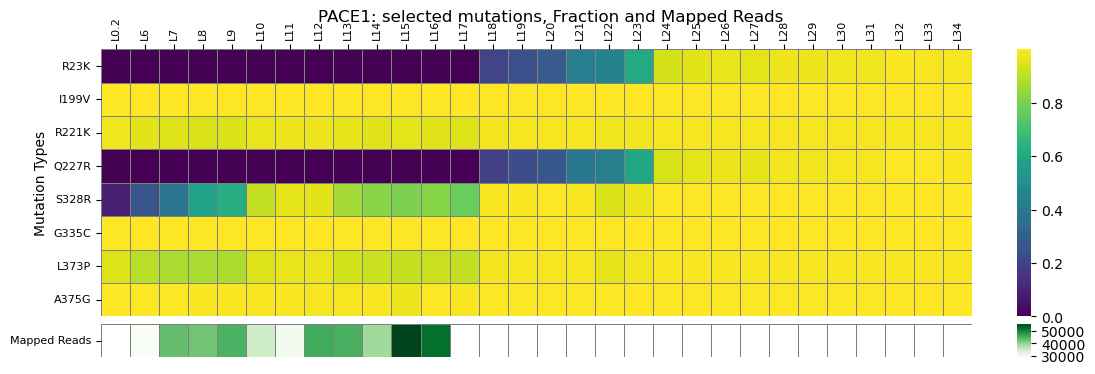

/mnt/G_Pharma/Users/tfang/Pacbio_SpCas9_old/Priscila_A6088/results/PACE1_selected_mutations_heatmap.pdf


In [40]:
# PACE3, restricted to a hand-picked set of mutation types
selected_muts = ['R23K', 'I199V', 'R221K', 'Q227R', 'S328R', 'G335C', 'L373P', 'A375G']

missing = [m for m in selected_muts if m not in Muts_Pace1.index]
if missing:
    print('Not present in Muts_Pace1.index:', missing)

Muts_Pace1_selected = Muts_Pace1.loc[[m for m in selected_muts if m in Muts_Pace1.index]]

fig_pace1_selected = plot_fraction_ct_lagoon_mapped_heatmap(
    Muts_Pace1_selected, samples_3,
    figsize=(12, 4), cmap="viridis",
    title="PACE1: selected mutations, Fraction and Mapped Reads")

out_pdf = f'{result_folder}/PACE1_selected_mutations_heatmap.pdf'
fig_pace1_selected.savefig(out_pdf, bbox_inches='tight', dpi=600)
print(out_pdf)



In [41]:
samples = pd.read_excel(f'{result_folder}/samples_info.xlsx')
samples['gt_dist'] = samples.Sample.map(gt_dist_file)
samples['aa_dist'] = samples.Sample.map(aa_dist_file)
print(samples.shape)

samples=samples.set_index('Sample')
samples['real_time_point'] = samples.index
samples['real_time_point_1'] =  samples['real_time_point'].apply(lambda x: float(x.split('_L')[-1]))
samples



(49, 8)


,Read Count,fastq,total_reads,mapped_reads,full_reads,gt_dist,aa_dist,real_time_point,real_time_point_1
Sample,,,,,,,,,
A6-09_L8,102668,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,102669,89,86,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-09_L8,8.0
A6-08_L28,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,182899,45297,44590,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L28,28.0
A6-09_L7,73711,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,73711,83,80,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-09_L7,7.0
A6-08_L27,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,124628,53690,52820,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L27,27.0
A6-08_L10,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,97123,43027,42389,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L10,10.0
...,...,...,...,...,...,...,...,...,...
A6-09_L4,101729,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,101781,35630,34125,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-09_L4,4.0
A6-08_L13,142535,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,142565,49080,48365,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L13,13.0
A6-08_L9,115494,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,115550,51661,51005,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L9,9.0


In [42]:

samples_1=samples.loc[samples['real_time_point'].str.contains("A6-08"),:]
samples_1

,Read Count,fastq,total_reads,mapped_reads,full_reads,gt_dist,aa_dist,real_time_point,real_time_point_1
Sample,,,,,,,,,
A6-08_L28,182861,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,182899,45297,44590,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L28,28.0
A6-08_L27,124556,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,124628,53690,52820,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L27,27.0
A6-08_L10,97085,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,97123,43027,42389,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L10,10.0
A6-08_L24,132402,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,132454,59897,58957,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L24,24.0
A6-08_L16,114980,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,115026,54200,53506,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L16,16.0
...,...,...,...,...,...,...,...,...,...
A6-08_L21,122382,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,122442,65843,63024,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L21,21.0
A6-08_L13,142535,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,142565,49080,48365,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L13,13.0
A6-08_L9,115494,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/fastq...,115550,51661,51005,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/g...,/mnt/mnemo1/Pacbio_SpCas9/Priscila_A6088/out/a...,A6-08_L9,9.0


In [43]:


def compute_gt_result(gt_file,checked_mutations):
    df_gt = pd.read_csv(gt_file)
    return (df_gt["Fraction"] * df_gt["Mutations"].apply(lambda m: 1 if all(mut in m for mut in checked_mutations) else 0)).sum()

anchor_mutation= "E116G" #"Y52F"
co_mutations1=pd.DataFrame(columns=samples_1.real_time_point)
for mutation in sorted(Muts_Pace1.index, key=lambda x: int(''.join(filter(str.isdigit, x)))):
    if mutation != anchor_mutation:
        checked_mutations=[anchor_mutation, mutation]
        co_mutations1.loc["_".join(checked_mutations),:] = samples_1["gt_dist"].apply(compute_gt_result, checked_mutations=checked_mutations)
        #samples_1["_".join(checked_mutations)] = samples_1["gt_dist"].apply(compute_gt_result, checked_mutations=checked_mutations)
# 1 mintues



Index(['L0.2', 'L6', 'L7', 'L8', 'L9', 'L10', 'L11', 'L12', 'L13', 'L14',
       'L15', 'L16', 'L17', 'L18', 'L19', 'L20', 'L21', 'L22', 'L23', 'L24',
       'L25', 'L26', 'L27', 'L28', 'L29', 'L30', 'L31', 'L32', 'L33', 'L34'],
      dtype='object')
(20, 30)
                 L0.2        L6        L7       L8        L9       L10  \
E116G_A16V        0.0       0.0       0.0      0.0       0.0       0.0   
E116G_R23K   0.000019  0.000022       0.0      0.0   0.00002       0.0   
E116G_Y52F        0.0       0.0       0.0      0.0       0.0       0.0   
E116G_N85D        0.0       0.0       0.0      0.0       0.0       0.0   
E116G_F93S        0.0       0.0       0.0      0.0       0.0       0.0   
...               ...       ...       ...      ...       ...       ...   
E116G_N343D       0.0       0.0       0.0      0.0       0.0       0.0   
E116G_L373P  0.000057  0.000065  0.000082  0.00012  0.000157  0.000731   
E116G_A375G  0.000057  0.000065  0.000082  0.00018  0.000176  0.000731   


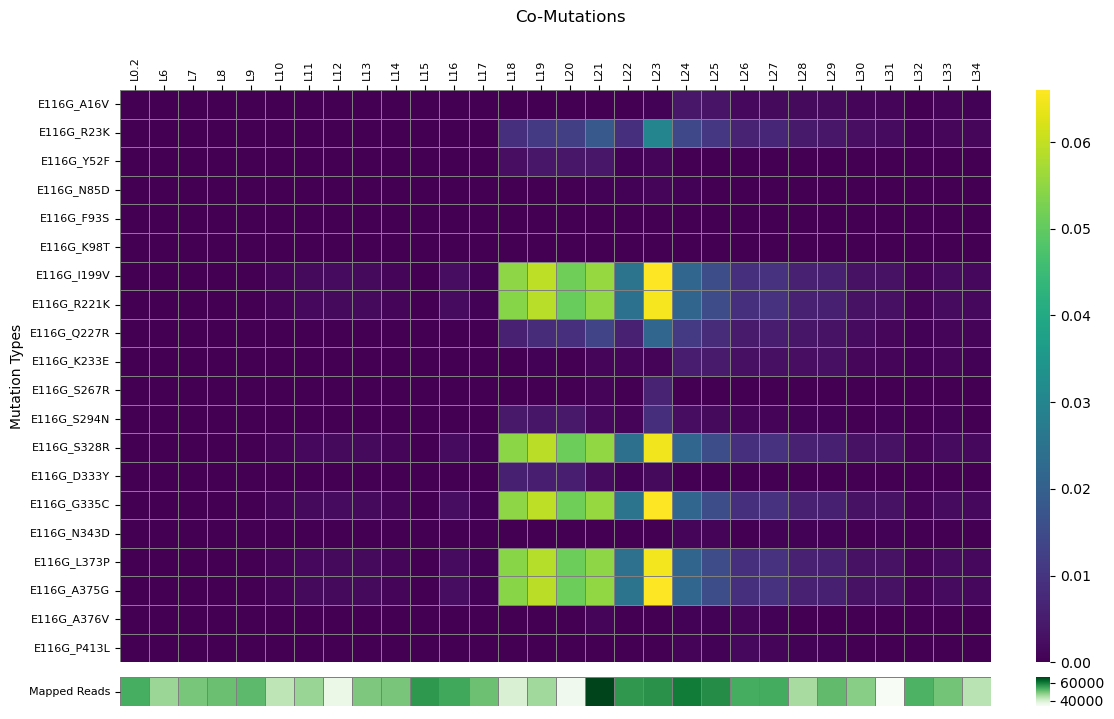

In [44]:
def temp_plot_fraction_ct_lagoon_mapped_heatmap(heatmap_data, samples, figsize=(20, 16), cmap="viridis", title=""):
    import matplotlib.gridspec as gridspec
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt

    # Sort columns based on the numeric value after '_T'
    sorted_columns = sorted(heatmap_data.columns, key=lambda col: float(col.split('_L')[-1]))
    hours = [float(col.split('_L')[-1]) for col in sorted_columns]

    # Mapped reads
    mapped_reads = samples.set_index("real_time_point_1").reindex(hours)["mapped_reads"].values

    # Reorder heatmap_data and adjust column labels
    heatmap_data = heatmap_data.reindex(columns=sorted_columns)
    heatmap_data.columns = [col.split("_")[-1] for col in heatmap_data.columns]
    print(heatmap_data.columns)

    try:
        sorted_index = sorted(heatmap_data.index, key=lambda x: int(x[1:-1]))
    except Exception:
        sorted_index = heatmap_data.index
    heatmap_data = heatmap_data.reindex(index=sorted_index)
    print(heatmap_data.shape)
    print(heatmap_data)

    heatmap_data=heatmap_data.astype(float)

    # Set up a gridspec with two rows; the top is larger
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(2, 2, width_ratios=[len(heatmap_data.columns), 0.5],
                           height_ratios=[len(heatmap_data.index), 1],
                           wspace=0.1, hspace=0.05)

    # Top: Fraction heatmap
    ax0 = plt.subplot(gs[0,0])
    ax0_cbar= plt.subplot(gs[0, 1])  # color bar at row 0, column 1
    sns.heatmap(heatmap_data, cmap=cmap, ax=ax0, cbar=True, cbar_ax=ax0_cbar,
                xticklabels=heatmap_data.columns, yticklabels=heatmap_data.index,
                linewidths=0.5, linecolor='gray')  # Add grid lines
    ax0.set_yticklabels(ax0.get_yticklabels(), rotation=0, fontsize=8)
    ax0.set_ylabel("Mutation Types")
    ax0.xaxis.tick_top()
    max_ticks = 100  # Maximum number of x-tick labels to display
    n_columns = len(heatmap_data.columns)
    if n_columns > max_ticks:
        tick_indices = np.linspace(0, n_columns - 1, max_ticks, dtype=int)
        ax0.set_xticks(tick_indices)
        ax0.set_xticklabels([heatmap_data.columns[i] for i in tick_indices], rotation=90, fontsize=8)
    else:
        ax0.set_xticklabels(ax0.get_xticklabels(), rotation=90, fontsize=8)

    # Second: mapped_reads heatmap
    mapped_array = np.reshape(mapped_reads, (1, -1))
    print(mapped_array.shape)
    ax1 = plt.subplot(gs[1,0])
    ax1_cbar = plt.subplot(gs[1, 1])  # color bar at row 1, column 1
    sns.heatmap(mapped_array, cmap="Greens", ax=ax1, cbar=True, cbar_ax=ax1_cbar,
                xticklabels=False, yticklabels=["Mapped Reads"],
                linewidths=0.5, linecolor='gray')  # Add grid lines
    ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0, fontsize=8)

    plt.suptitle(title)
    plt.show()

test=temp_plot_fraction_ct_lagoon_mapped_heatmap(co_mutations1, samples_1,
                                       figsize=(12, 8), cmap="viridis",
                                       title="Co-Mutations")

In [45]:

def compute_gt_result(gt_file,checked_mutations):
    df_gt = pd.read_csv(gt_file)
    return (df_gt["Fraction"] * df_gt["Mutations"].apply(lambda m: 1 if all(mut in m for mut in checked_mutations) else 0)).sum()

anchor_mutation= anchor_mutation
co_mutations1=pd.DataFrame(columns=samples_1.real_time_point)
for mutation in sorted(Muts_Pace1.index, key=lambda x: int(''.join(filter(str.isdigit, x)))):
    if mutation != anchor_mutation:
        checked_mutations=[anchor_mutation, mutation]
        co_mutations1.loc["_".join(checked_mutations),:] = samples_1["gt_dist"].apply(compute_gt_result, checked_mutations=checked_mutations)
        #samples_1["_".join(checked_mutations)] = samples_1["gt_dist"].apply(compute_gt_result, checked_mutations=checked_mutations)
# 1 mintues

